# Computational Probability & Statistics

This notebook covers the code-oriented problem sets at my Computational Prrobability & Statistics course. I plan on adding the theoretical problems later on using LaTeX, eventually.

In [ ]:
%pip -q install matplotlib
%pip -q  install scipy
%pip -q install numpy

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


## PSet 1: Introduction to Probability


In [8]:
import scipy
import matplotlib.pyplot as plt
import numpy as np

**Exercise 26.** [Wasserman 2003 (1.10.21)]  
Una moneda tiene probabilidad $p$ de salir cara. Si se lanza muchas veces, esperamos que la proporción de caras se acerque a $p$. Considere $p = 0.3$ y simule $n$ lanzamientos, con $n = 1, \dots, 1000$. Grafique la proporción de caras en función del número de lanzamientos. Repita con $p = 0.03$.

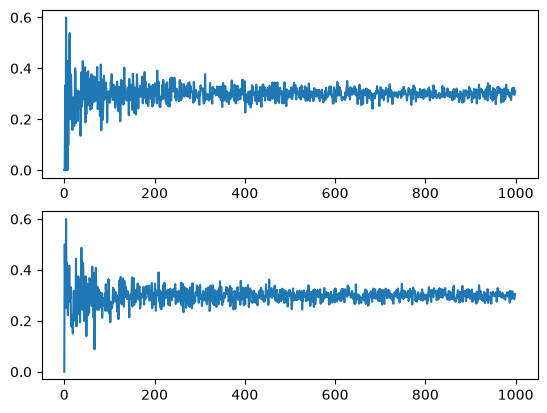

In [9]:
from scipy.stats import binom

heads_proportion = {0.3: [],
                    0.03:[]}

for i in range(1,1001):
    heads_proportion[0.3].append(binom.rvs(n=i,p=0.3)/i)
    heads_proportion[0.03].append(binom.rvs(n=i,p=0.3)/i)


experiment_count = np.arange(1000)

fig, (ax1,ax2) = plt.subplots(2)
ax1.plot(experiment_count, heads_proportion[0.3])
ax2.plot(experiment_count, heads_proportion[0.03])
plt.show()



**Ejercicio 27.** [Wasserman 2003 (1.10.22)]  
Suponga que lanzamos una moneda $n$ veces, con probabilidad $p$ de salir cara. Sea $X$ el número de caras. La intuición sugiere que, si $n$ es grande, $X$ debería estar cerca de $np$. Simule este experimento muchas veces (pruebe con $p = 0.3$ y $n = 10, 100$ y $1000$) y promedie los valores obtenidos de $X$ en cada caso. Compare dichos promedios con $np$.

In [10]:
head_counts = {10:0,
               100:0,
               1000:0
                }

heads_proportion = {10:[],
               100:[],
               1000:[]
                }

for n in [10,100,1000]:
    head_counts[n] = binom.rvs(n=n,p=0.3)
    heads_proportion[n].append(head_counts[n]/n)

for n in [10,100,1000]:
    print(f"(n={n},p=0.3) Expected: 3  Actual: {heads_proportion[n][0]}\n")

(n=10,p=0.3) Expected: 3  Actual: 0.7

(n=100,p=0.3) Expected: 3  Actual: 0.32

(n=1000,p=0.3) Expected: 3  Actual: 0.283



**Ejercicio 28.** [Wasserman 2003 (1.10.23)]  
Suponga que lanzamos un dado justo. Sean $A = \{2, 4, 6\}$ y $B = \{1, 2, 3, 4\}$. Entonces $P(A) = 1/2$, $P(B) = 2/3$, $P(A \cap B) = 1/3$, y se verifica que $P(A \cap B) = P(A)P(B)$, por lo tanto $A$ y $B$ son independientes. Simule lanzamientos y calcule frecuencias relativas $\hat{P}(A)$, $\hat{P}(B)$ y $\hat{P}(A \cap B)$ para verificar esta relación. Luego, busque dos eventos que no sean independientes, calcule nuevamente esas frecuencias y compare con los valores teóricos. Interprete los resultados.

In [11]:
from scipy.stats import randint #Scipy's discrete uniform is randint, not very intuitive in my opinion but ok

A = {2,4,6}
B = {1,2,3,4}
AnB = {2,4}

A_count, B_count, AnB_count = 0,0,0

for _ in range(6000):
    landing_side = randint.rvs(1,7)
    if landing_side in A: A_count+=1
    if landing_side in B: B_count+=1
    if landing_side in AnB: AnB_count+=1

print(f"Relative frequencies: \nP(A)={'{0:.2g}'.format(A_count/6000)}\nP(B)={'{0:.2g}'.format(B_count/6000)}\nP(AnB)={'{0:.2g}'.format(AnB_count/6000)}")



Relative frequencies: 
P(A)=0.5
P(B)=0.66
P(AnB)=0.33


**Ejercicio 29 (Continuación)** [De paseo por el casino de Monte Carlo en 1913]  
a) Cuente la cantidad de veces que ocurrieron 5 caras consecutivas. Compare con la cantidad de veces que ocurrió la siguiente secuencia específica: $\text{CXCCX}$ (o casi cualquier otra). ¿Son similares?  
b) Cuente la cantidad de veces que una secuencia de 5 caras consecutivas fue seguida por una ceca. Idem pero seguida por otra cara. ¿Son similares?  
c) “La probabilidad de 6 caras consecutivas es mucho menor que la de 5 caras consecutivas. Por eso si veo 5 caras seguidas en la siguiente tirada apuesto a cruz”. Explique cuál es la lógica en esta falla. Defina claramente el experimento, el espacio muestral y el evento por el cual está apostando.  
d) ¿Qué pasa con el análisis si permite superposición al agrupar de a 5 tiradas?

In [12]:
allHeadsCount = 0
specificPatternCount = 0

for _ in range(1000):
    pattern = [0,0,0,0,0]    
    for i in range(5):
        pattern[i] = binom.rvs(n=1,p=0.5)

    if (pattern == [1,1,1,1,1]):
        allHeadsCount += 1
    if (pattern == [1,0,1,1,0]):
        specificPatternCount += 1
    
print(allHeadsCount, specificPatternCount)

32 24


**Ejercicio 30.** [(Equilibrando una moneda desequilibrada$^2$)]  
Una moneda desequilibrada tiene probabilidad $p < 0.5$ de salir cara.

a) Elija un valor de $p$ y simule $n = 100000$ lanzamientos. Grafique la cantidad de caras y cruces, compare con los valores esperados $np$ y $n(1 - p)$.  
b) Tome la secuencia de lanzamientos de recién y agrupe los lanzamientos consecutivos de a pares, como si el experimento en realidad hubiera sido “arroje dos veces una moneda”. ¿Cuáles son los eventos posibles? Grafique la cantidad de cada tipo y note que dos de ellos son prácticamente equiprobables. ¿A qué se debe? ¿Depende del valor de $p$? Defina un algoritmo apropiado para obtener resultados equiprobables utilizando este fenómeno.  
c) Calcule el número promedio de lanzamientos entre ocurrencias consecutivas de cualquiera de los eventos equiprobables. Repita para muchos valores de $0 < p < 0.5$ y grafique en función de $p$. Discuta la eficiencia del algoritmo.

## PSet 2: Random Variables

**Exercise 28. [ProbEst 2024, guide 2 (4,6)]**  
Define a function that, given two vectors $x = (x_1, \dots, x_n)$ and $p = (p_1, \dots, p_n)$, estimates the expectation and variance of the discrete random variable that takes values $x_1, \dots, x_n$ with probabilities $p_1, \dots, p_n$ respectively.


In [ ]:
def f(x, p):
    expectation = 

**Exercise 29. [some proofs in Casella Berger 2024 (sections 3.2 and 3.3)]**  
Make histograms of large samples and graphically verify the similarity of the following distributions:

1. $X \sim \text{Bin}(n, p)$ versus $X \sim \text{Poisson}(np)$ in the case of large $n$ and small $p$.
2. $X \sim \text{Bin}(n, p)$ versus $X \sim \text{Normal}(np, np(1 - p))$ in the case of large $n$ and $p$ not close to $0$ or $1$.
3. $X \sim \text{Gamma}(\alpha, \beta)$ versus $X \sim \text{Normal}(\alpha, \beta)$ versus $X \sim \text{Normal}(\alpha/\beta, \alpha/\beta^2)$ in the case of $\alpha \gg \beta$.
4. $X \sim \text{Student}(n)$ versus $X \sim \text{Normal}(0, 1)$ in the case of large $n$.



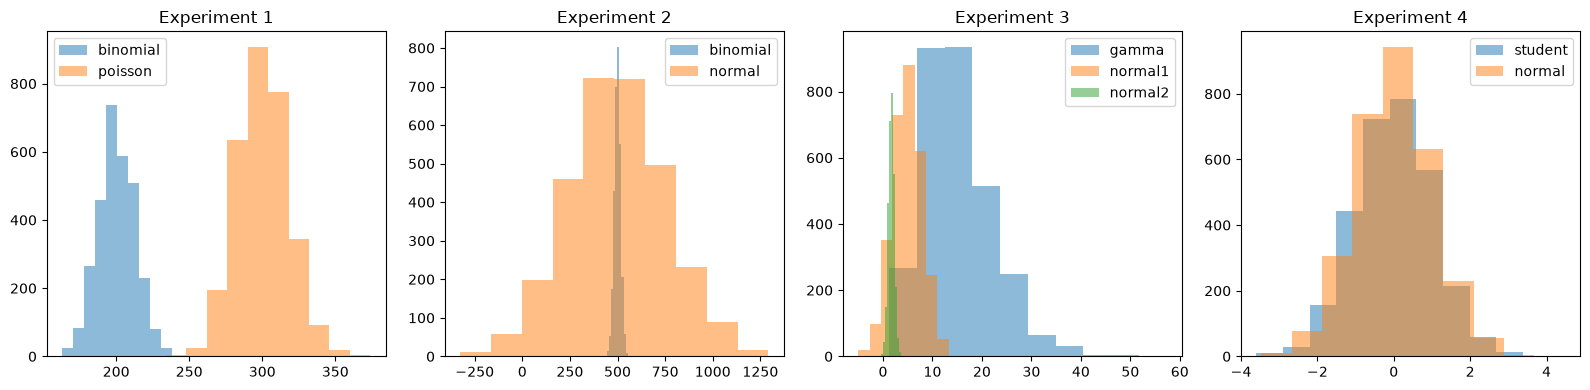

In [40]:
from scipy.stats import binom, poisson, norm, gamma, t


experiments = {
    "experiment_1": {"binomial": [], "poisson": []},
    "experiment_2": {"binomial": [], "normal": []},
    "experiment_3": {"gamma": [], "normal1": [], "normal2": []},
    "experiment_4": {"student": [], "normal": []}
}

n = 3000


fig, axs = plt.subplots(1, 4, figsize=(16, 4))

for _ in range(n):
    experiments["experiment_1"]["binomial"].append(binom.rvs(1000, 0.2))
    experiments["experiment_1"]["poisson"].append(poisson.rvs(300))

    experiments["experiment_2"]["binomial"].append(binom.rvs(1000, 0.5))
    experiments["experiment_2"]["normal"].append(norm.rvs(500, 500 * 0.5))

    experiments["experiment_3"]["gamma"].append(gamma.rvs(5, scale=3))
    experiments["experiment_3"]["normal1"].append(norm.rvs(5, 3))
    experiments["experiment_3"]["normal2"].append(norm.rvs(5/3, 5/9))

    experiments["experiment_4"]["student"].append(t.rvs(n))
    experiments["experiment_4"]["normal"].append(norm.rvs(0, 1))


exp_values = list(experiments.values())

for i, exp_dict in enumerate(exp_values):
    for dist_name, data in exp_dict.items():
        
        axs[i].hist(data, alpha=0.5, label=dist_name)
    
    axs[i].legend()
    axs[i].set_title(f"Experiment {i + 1}")

plt.tight_layout()
plt.show()

**Exercise 30. [ProbEst 2024, guide 3 (25)]**  
Transformation of variables. Plot the result as a histogram and compare with the theoretical distribution.

a) Using Exercise 17 part a), generate a random variable with distribution $\text{U}(3, 8)$ from a $\text{U}(0, 1)$.  
b) Using Exercise 17 part d), generate a random variable with distribution $\text{Exp}(10)$ from a $\text{U}(0, 1)$.  
c) Generate a random variable with the following discrete uniform distribution: $p_X(k) = \frac{1}{100}$ with $k = 0, 1, \dots, 99$ from a $\text{U}(0, 1)$.  
d) Generate a random variable with distribution $\text{Bin}(1, 1/3)$ from a $\text{U}(0, 1)$.  
e) Generate a random variable with distribution $\text{Poisson}(5)$ from a $\text{U}(0, 1)$.  

**Exercise 31. [Wasserman 2003 (2.14) (18)]**  
Let $X \sim N(3, 16)$. Solve the following using a numerical integrator.

a) Calculate $P(X < 7)$; $P(X > -2)$; $P(0 \le X < 4)$.  
b) Find $x$ such that $P(X > x) = 0.05$. Find $x$ such that $P(|X| > |x|) = 0.05$.  

Alternatively, how would you solve it if you had a sample of $n = 10000$ data points?